In [ ]:
!python imageconverter.py

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, top_k_accuracy_score
from transformers import color_histogram
from pathlib import Path
import matplotlib.pyplot as plt


In [95]:
train_df = pd.read_csv("train_set.csv")
test_df = pd.read_csv("test_set.csv")

In [96]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96079 entries, 0 to 96078
Columns: 147 entries, country_code to edge_density_bottom
dtypes: bool(1), float64(134), int64(5), str(7)
memory usage: 118.6 MB


In [97]:

feature_cols = [c for c in train_df.columns if c not in ["country", "image_name"]]



missing = train_df[feature_cols].isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
missing_df = missing_df[missing_df["Missing Count"] > 0].sort_values("Missing %", ascending=False)
print(missing_df.to_string())

                    Missing Count  Missing %
country_code                  897       0.93
coord_country_code            888       0.92


In [98]:
print(train_df.index.is_unique, train_df.index.max(), len(train_df))
print(test_df.index.is_unique, test_df.index.max(), len(test_df))

True 96078 96079
True 10675 10676


In [99]:
missing_cc = train_df[train_df['country_code'].isna()]
print(missing_cc.groupby('country').size().sort_values(ascending=False))

country
Namibia         877
Botswana         14
South Africa      6
dtype: int64


Missing values are because of Namibia " NA ". Thats fine well drop all but country they all the same. 

In [100]:

feature_cols = [c for c in train_df.columns if c not in ["country", "image_name"]]



missing = train_df[feature_cols].isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
missing_df = missing_df[missing_df["Missing Count"] > 0].sort_values("Missing %", ascending=False)
print(missing_df.to_string())

                    Missing Count  Missing %
country_code                  897       0.93
coord_country_code            888       0.92


In [101]:
train_df.keys()

Index(['country_code', 'image_name', 'width', 'height', 'size', 'path',
       'latitude', 'longitude', 'heading', 'country',
       ...
       'lbp_39', 'ground_hue_mean', 'ground_sat_mean', 'ground_val_mean',
       'ground_grey_frac', 'brightness_mean', 'contrast_std',
       'edge_density_total', 'edge_density_top', 'edge_density_bottom'],
      dtype='str', length=147)

In [102]:
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr_matrix = train_df[numeric_cols].corr()

corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
high_corr = corr_pairs[corr_pairs.abs() > 0.8].sort_values(ascending=False)

print(high_corr)

size                edge_density_total     0.966164
lbp_0               lbp_9                  0.958615
lbp_10              lbp_19                 0.955514
lbp_1               lbp_9                  0.955226
vari_mean           vari_std               0.953062
lbp_11              lbp_19                 0.951424
lbp_30              lbp_39                 0.932188
lbp_20              lbp_29                 0.932166
lbp_0               lbp_1                  0.922506
lbp_10              lbp_11                 0.920591
hsv_bin_29          hsv_bin_30             0.906666
size                edge_density_top       0.894092
edge_density_total  edge_density_top       0.891680
lbp_31              lbp_39                 0.873769
lbp_21              lbp_29                 0.870919
hsv_bin_28          hsv_bin_29             0.865025
lbp_20              lbp_21                 0.844294
lbp_30              lbp_31                 0.840320
hsv_bin_30          hsv_bin_31             0.836538
hsv_bin_34  

In [104]:
DATA_PATH = Path("data/images/streetview_images")

if not any(DATA_PATH.iterdir()):
    path = kagglehub.dataset_download(
        "sylshaw/streetview-by-country",
        output_dir=str(DATA_PATH)
    )
else:
    path = str(DATA_PATH)

print("Path to dataset:", path)

Path to dataset: data/images/streetview_images


In [105]:
old_hsv_cols = [c for c in train_df.columns if c.startswith('hsv_bin_')]
train_df = train_df.drop(columns=old_hsv_cols)
test_df = test_df.drop(columns=old_hsv_cols)

train_features = [color_histogram(path) for path in train_df['path']]
test_features = [color_histogram(path) for path in test_df['path']]

train_hsv_cols = pd.DataFrame(train_features, columns=[f'hsv_bin_{i}' for i in range(48)])
test_hsv_cols = pd.DataFrame(test_features, columns=[f'hsv_bin_{i}' for i in range(48)])

train_df = pd.concat([train_df.reset_index(drop=True), train_hsv_cols], axis=1)
test_df = pd.concat([test_df.reset_index(drop=True), test_hsv_cols], axis=1)

In [106]:
from sklearn.decomposition import PCA

def fit_full_pca(df):
    lbp_cols = [c for c in df.columns if c.startswith('lbp')]
    pca = PCA()
    pca.fit(df[lbp_cols])
    return pca

In [107]:

pca = fit_full_pca(train_df)

In [108]:
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)
print("Cumulative Variance:")
print(cumulative_variance)
print(f"Components for 80% variance: {np.argmax(cumulative_variance >= 0.80) + 1}")


Cumulative Variance:
[0.36931468 0.59649358 0.71509513 0.79284805 0.85406926 0.89512261
 0.93000495 0.94400384 0.95587638 0.96481216 0.96988139 0.97435668
 0.97786711 0.9802181  0.98246554 0.98445001 0.98576217 0.98702394
 0.9881589  0.9892409  0.99026265 0.9911956  0.99207872 0.99292138
 0.99368065 0.99440114 0.99511061 0.99577117 0.99642418 0.99704158
 0.99760882 0.99815381 0.99864783 0.99911758 0.99958382 1.
 1.         1.         1.         1.        ]
Components for 80% variance: 5


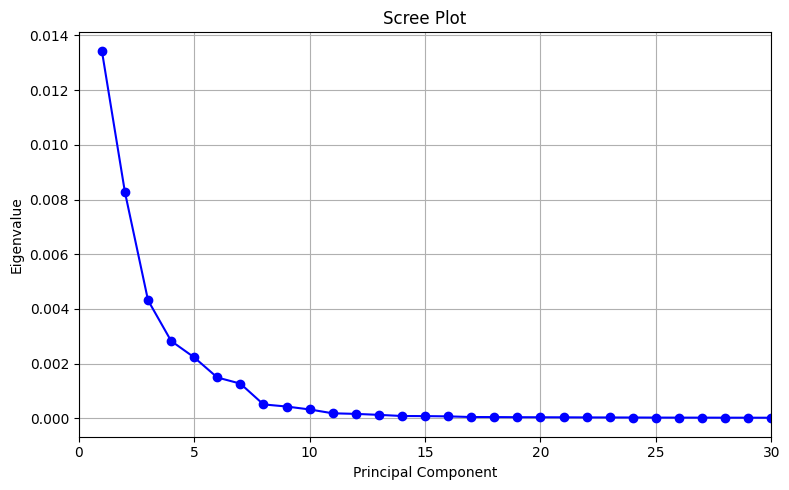

In [ ]:

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues)+1), eigenvalues, marker='o', linestyle='-', color='blue')
plt.title("Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.xlim(0, 30)
plt.grid(True)
plt.tight_layout()
plt.show()



In [110]:

n_pca_components = 7

def apply_pca_to_lbp(df, n_components):
    lbp_cols = [c for c in df.columns if c.startswith('lbp')]
    pca = PCA(n_components=n_components)
    lbp_pca = pca.fit_transform(df[lbp_cols])
    lbp_pca_cols = pd.DataFrame(lbp_pca, columns=[f'lbp_pca_{i}' for i in range(lbp_pca.shape[1])])
    df = pd.concat([df.drop(columns=lbp_cols).reset_index(drop=True), lbp_pca_cols], axis=1)
    return df, pca

def transform_pca_lbp(df, pca):
    lbp_cols = [c for c in df.columns if c.startswith('lbp')]
    lbp_pca = pca.transform(df[lbp_cols])
    lbp_pca_cols = pd.DataFrame(lbp_pca, columns=[f'lbp_pca_{i}' for i in range(lbp_pca.shape[1])])
    df = pd.concat([df.drop(columns=lbp_cols).reset_index(drop=True), lbp_pca_cols], axis=1)
    return df


In [111]:
train_df, pca = apply_pca_to_lbp(train_df, n_pca_components)
test_df = transform_pca_lbp(test_df, pca)

In [112]:
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr_matrix = train_df[numeric_cols].corr()

corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
high_corr = corr_pairs[corr_pairs.abs() > 0.8].sort_values(ascending=False)

print(high_corr)

size                edge_density_total     0.966164
vari_mean           vari_std               0.953062
hsv_bin_29          hsv_bin_30             0.906666
size                edge_density_top       0.894092
edge_density_total  edge_density_top       0.891680
hsv_bin_28          hsv_bin_29             0.865025
hsv_bin_30          hsv_bin_31             0.836538
hsv_bin_34          hsv_bin_35             0.835752
hsv_bin_33          hsv_bin_34             0.827221
edge_density_total  edge_density_bottom    0.802613
dtype: float64


In [ ]:
from sklearn.feature_selection import f_classif


feature_cols = [c for c in numeric_cols if c not in ['latitude', 'longitude', 'heading']]
f_scores, p_values = f_classif(train_df[feature_cols], train_df['country'])

feature_importance = pd.Series(f_scores, index=feature_cols).sort_values(ascending=False)
print(feature_importance)

sky_fraction    655.269559
lbp_pca_2       484.828946
size            438.704084
hog_pca_0       436.532367
contrast_std    363.839147
                   ...    
lbp_pca_3         1.904695
lbp_pca_4         1.834298
width                  NaN
height                 NaN
channels               NaN
Length: 103, dtype: float64


/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [0 1 3] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [114]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(train_df[feature_cols], train_df['country'], random_state=42)
mi_importance = pd.Series(mi_scores, index=feature_cols).sort_values(ascending=False)
print(mi_importance)

sky_fraction    0.370436
hsv_bin_47      0.309377
hsv_bin_31      0.299402
vari_mean       0.290499
hsv_bin_46      0.290084
                  ...   
lbp_pca_3       0.024259
lbp_pca_4       0.021573
width           0.001093
height          0.000000
channels        0.000000
Length: 103, dtype: float64


In [115]:
drop_cols = ['country_code', 'width', 'height', 'size', 'path', 'coord_country_code',
             'corrupted', 'channels', 'phash', 'latitude', 'vari_std', 'longitude', 'hsv_bin_34', 'hsv_bin_29', 'edge_density_total', 'continent']

train_df = train_df.drop(columns=drop_cols)
test_df = test_df.drop(columns=drop_cols)

In [118]:
f_scores_series = pd.Series(f_scores, index=feature_cols)

In [120]:
mi_threshold = mi_importance.quantile(0.2)
f_threshold = feature_importance.quantile(0.2)

drop_cols2 = [c for c in feature_cols if mi_importance[c] <= mi_threshold and f_scores_series[c] <= f_threshold]

In [121]:
train_df = train_df.drop(columns=drop_cols2)
test_df = test_df.drop(columns=drop_cols2)

In [ ]:
skewness = train_df[feature_cols].skew().sort_values(ascending=False)

skewed_features = skewness[(skewness > 2) | (skewness < -2)]
skewed_df = pd.DataFrame({'feature': skewed_features.index, 'skewness': skewed_features.values})
print(skewed_df)

hsv_bin_32    34.094460
hsv_bin_14     7.066895
vari_mean      6.949759
hsv_bin_30     6.792065
hsv_bin_28     6.784120
hsv_bin_13     6.439854
hsv_bin_27     5.190380
hsv_bin_15     5.092590
hsv_bin_12     4.709504
hsv_bin_11     4.433482
hsv_bin_33     4.206103
hsv_bin_26     4.026585
hsv_bin_31     3.725032
hsv_bin_5      3.327745
hsv_bin_6      3.087945
hsv_bin_25     2.989727
hsv_bin_7      2.944304
hsv_bin_10     2.807677
hsv_bin_4      2.493907
hsv_bin_24     2.396733
hsv_bin_35     2.259421
hsv_bin_23     2.063125
hsv_bin_0      2.024697
lbp_pca_2     -2.436208
dtype: float64
       feature   skewness
0   hsv_bin_32  34.094460
1   hsv_bin_14   7.066895
2    vari_mean   6.949759
3   hsv_bin_30   6.792065
4   hsv_bin_28   6.784120
5   hsv_bin_13   6.439854
6   hsv_bin_27   5.190380
7   hsv_bin_15   5.092590
8   hsv_bin_12   4.709504
9   hsv_bin_11   4.433482
10  hsv_bin_33   4.206103
11  hsv_bin_26   4.026585
12  hsv_bin_31   3.725032
13   hsv_bin_5   3.327745
14   hsv_bin_6   3.

In [126]:
print((train_df[skewed_df['feature']] < 0).sum())

hsv_bin_32        0
hsv_bin_14        0
vari_mean     14008
hsv_bin_30        0
hsv_bin_28        0
hsv_bin_13        0
hsv_bin_27        0
hsv_bin_15        0
hsv_bin_12        0
hsv_bin_11        0
hsv_bin_33        0
hsv_bin_26        0
hsv_bin_31        0
hsv_bin_5         0
hsv_bin_6         0
hsv_bin_25        0
hsv_bin_7         0
hsv_bin_10        0
hsv_bin_4         0
hsv_bin_24        0
hsv_bin_35        0
hsv_bin_23        0
hsv_bin_0         0
lbp_pca_2     32667
dtype: int64


In [127]:
neg_cols = ['vari_mean', 'lbp_pca_2']
log_cols = [c for c in skewed_df['feature'] if c not in neg_cols]

for col in log_cols:
    train_df[col] = np.log1p(train_df[col])
    test_df[col] = np.log1p(test_df[col])

for col in ['vari_mean']:
    train_df[col] = np.sign(train_df[col]) * np.log1p(np.abs(train_df[col]))
    test_df[col] = np.sign(test_df[col]) * np.log1p(np.abs(test_df[col]))

In [132]:
def winsorize_continuous_train_test(df_train, df_test, lower_pct=0.01, upper_pct=0.99):
    df_train = df_train.copy()
    df_test = df_test.copy()
    continuous_cols = [c for c in df_train.columns if c not in ["country", "image_name"]]

    for col in continuous_cols:
        if col in df_train.columns:
            lo = df_train[col].quantile(lower_pct)
            hi = df_train[col].quantile(upper_pct)
            n_outliers_train = ((df_train[col] < lo) | (df_train[col] > hi)).sum()
            df_train[col] = df_train[col].clip(lo, hi)
            df_test[col] = df_test[col].clip(lo, hi)

    return df_train, df_test

In [133]:
train_df, test_df = winsorize_continuous_train_test(train_df, test_df)

In [134]:
from sklearn.preprocessing import StandardScaler

feature_cols = [c for c in train_df.columns if c not in ["country", "image_name"]]


scaler = StandardScaler()
train_df[feature_cols] = scaler.fit_transform(train_df[feature_cols])
test_df[feature_cols] = scaler.transform(test_df[feature_cols])

In [129]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96079 entries, 0 to 96078
Data columns (total 82 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   image_name           96079 non-null  str    
 1   heading              96079 non-null  float64
 2   country              96079 non-null  str    
 3   vari_mean            96079 non-null  float64
 4   vari_frac            96079 non-null  float64
 5   sky_fraction         96079 non-null  float64
 6   sky_blue_ratio       96079 non-null  float64
 7   hog_pca_0            96079 non-null  float64
 8   hog_pca_1            96079 non-null  float64
 9   hog_pca_2            96079 non-null  float64
 10  hog_pca_3            96079 non-null  float64
 11  hog_pca_5            96079 non-null  float64
 12  hog_pca_7            96079 non-null  float64
 13  hog_pca_8            96079 non-null  float64
 14  hog_pca_11           96079 non-null  float64
 15  hog_pca_13           96079 non-null  float64
 1

In [136]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.10, random_state=42)
train_idx, val_idx = next(splitter.split(train_df, train_df["country"]))

train_split = train_df.iloc[train_idx]
val_split = train_df.iloc[val_idx]

In [ ]:
train_names = train_split["image_name"].copy()
val_names = val_split["image_name"].copy()
test_names = test_df["image_name"].copy()

y_train = train_split["country"].copy()
y_val = val_split["country"].copy()
y_test = test_df["country"].copy()

X_train_raw = train_split.drop(columns=["image_name", "country"]).copy()
X_val_raw = val_split.drop(columns=["image_name", "country"]).copy()
X_test_raw = test_df.drop(columns=["image_name", "country"]).copy()

print(f"training features shape: {X_train_raw.shape}")
print(f"validation features shape: {X_val_raw.shape}")
print(f"test features shape: {X_test_raw.shape}")

Raw training features shape: (86471, 80)
Raw validation features shape: (9608, 80)
Raw test features shape: (10676, 80)


In [ ]:

lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_raw, y_train)

val_probs = lr_model.predict_proba(X_val_raw)
val_pred = lr_model.predict(X_val_raw)

print("Accuracy:", accuracy_score(y_val, val_pred))
print("Top-3 Accuracy:", top_k_accuracy_score(y_val, val_probs, k=3, labels=lr_model.classes_))

top3_idx = np.argsort(val_probs, axis=1)[:, ::-1][:, :3]
top3_countries = lr_model.classes_[top3_idx]

results = pd.DataFrame({
    "true_country": y_val.values,
    "guess_1": top3_countries[:, 0],
    "guess_2": top3_countries[:, 1],
    "guess_3": top3_countries[:, 2],
})

results.head()

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_raw, y_train)

val_probs = dt_model.predict_proba(X_val_raw)
val_pred = dt_model.predict(X_val_raw)

print("Accuracy:", accuracy_score(y_val, val_pred))
print("Top-3 Accuracy:", top_k_accuracy_score(y_val, val_probs, k=3, labels=dt_model.classes_))

top3_idx = np.argsort(val_probs, axis=1)[:, ::-1][:, :3]
top3_countries = dt_model.classes_[top3_idx]

results_dt = pd.DataFrame({
    "true_country": y_val.values,
    "guess_1": top3_countries[:, 0],
    "guess_2": top3_countries[:, 1],
    "guess_3": top3_countries[:, 2],
})

results_dt.head()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=50, max_depth=15, n_jobs=-1, random_state=42)
rf_model.fit(X_train_raw, y_train)

val_probs = rf_model.predict_proba(X_val_raw)
val_pred = rf_model.predict(X_val_raw)

print("Accuracy:", accuracy_score(y_val, val_pred))
print("Top-3 Accuracy:", top_k_accuracy_score(y_val, val_probs, k=3, labels=rf_model.classes_))

top3_idx = np.argsort(val_probs, axis=1)[:, ::-1][:, :3]
top3_countries = rf_model.classes_[top3_idx]

results_rf = pd.DataFrame({
    "true_country": y_val.values,
    "guess_1": top3_countries[:, 0],
    "guess_2": top3_countries[:, 1],
    "guess_3": top3_countries[:, 2],
})

results_rf.head()

In [ ]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_raw, y_train)

val_probs = nb_model.predict_proba(X_val_raw)
val_pred = nb_model.predict(X_val_raw)

print("Accuracy:", accuracy_score(y_val, val_pred))
print("Top-3 Accuracy:", top_k_accuracy_score(y_val, val_probs, k=3, labels=nb_model.classes_))

top3_idx = np.argsort(val_probs, axis=1)[:, ::-1][:, :3]
top3_countries = nb_model.classes_[top3_idx]

results_nb = pd.DataFrame({
    "true_country": y_val.values,
    "guess_1": top3_countries[:, 0],
    "guess_2": top3_countries[:, 1],
    "guess_3": top3_countries[:, 2],
})

results_nb.head()